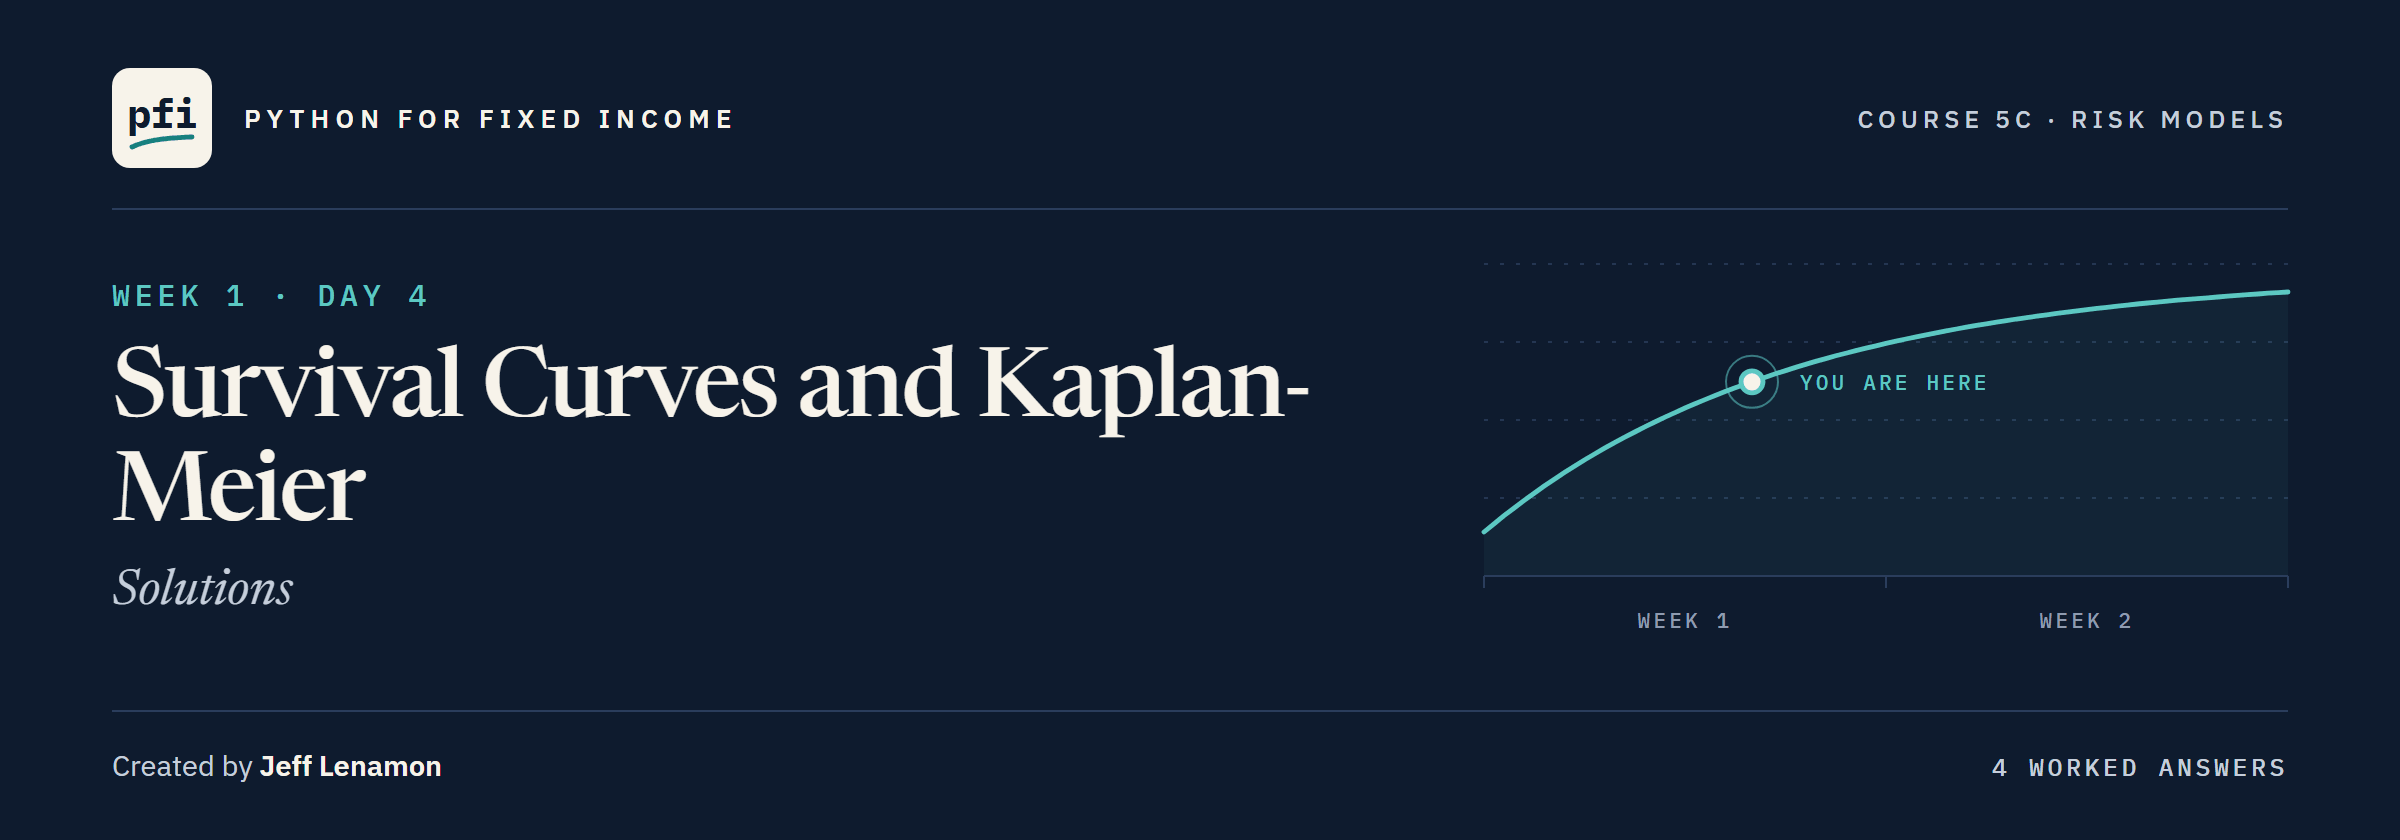

# Survival Curves and Kaplan-Meier: Solutions

Week 1, Day 4. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day4/04_survival_curves_and_kaplan_meier_solutions.ipynb)

# Problem Statement

## Business Context

Day 3 counted default rates per firm-year in the cohort of invented firms.
Today asks how long a firm stays free of default: the share of entrants still free after 1, 5 and 10 years since entry.
The trouble is that most firms are never seen to default.
They exit, refinanced or called, or are still watched when study year 14 ends.
A curve today is the share of these invented firms free of default t years after entry, study years 1 to 14, never a statement about a real firm, rating or coming year.
Years 15 to 20 stay closed until the capstone.

## Objectives

Turn firm-years into one row per firm with a time and an event, and tell a default from a censored watch.
Work Kaplan-Meier by hand and as a short function, and compare it with two shortcuts that mishandle censoring.
Fit the curve with statsmodels and read its Greenwood band.
Compare curves by rating at entry with the log-rank test.
Read the hazard year by year and the cumulative hazard, and set a flat hazard's curve beside the counted one.
Turn an invented spread and recovery into a hazard with the credit triangle.

## Data Dictionary

`course5c_cohort.csv`, one row per firm per study year (the columns used today):

1. `firm_id`: the firm, an invented id
2. `study_year`: 1 to 20, never a calendar year
3. `years_since_entry`: 1 in the firm's first year, 2 in its second, and so on
4. `rating`: the rating at the start of the year
5. `default`: 1 in the year the firm defaulted
6. `exit`: 1 in the year the firm left for a reason unrelated to default

`sector`, `rating_score`, `leverage` and `coverage` wait for Day 5.
`ratings.csv` is the course's rating scale: each `rating` and its `bucket`, AAA to CCC.

Made here: `firms` (one row per firm), `km` (the cohort's curve), `curve` (the same from statsmodels) and `hazard`.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# the chi-squared curve (Course 5B's Day 4), and statsmodels' survival curve and log-rank test
from scipy import stats
from statsmodels.duration.survfunc import SurvfuncRight, survdiff

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Cohort and the Rating Scale

In [3]:
# the synthetic cohort, one row per firm per study year, and the course's rating scale (18 rows, a lookup)
cohort = pd.read_csv(DATA + "course5c_cohort.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
print(cohort.shape, "| firms:", cohort["firm_id"].nunique(), "| rating scale:", ratings.shape)

(29615, 10) | firms: 4000 | rating scale: (18, 4)


## The Development Years Only

In [4]:
# Day 3's cut: study years 1 to 14; the later years are counted and left alone
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END].copy()
print("Development firm-years:", len(development), "| held-out firm-years:", len(cohort) - len(development))

Development firm-years: 18503 | held-out firm-years: 11112


**Day 3's cut holds: every curve today comes from study years 1 to 14.**

# Data Overview

## One Row per Firm

Day 3 checked these rows: no blanks, no repeated firm-year, and a default or an exit only in a firm's last row.
Today the clock is **years since entry**, and a firm's **watch** runs from its entry to its last development row.

In [5]:
# one row per firm with named aggregation (Course 1): years watched, how the watch ended, entry year and rating
firms = development.groupby("firm_id").agg(years=("years_since_entry", "max"), defaulted=("default", "max"),
                                           exited=("exit", "max"), entry_year=("study_year", "min"),
                                           entry_rating=("rating", "first"))
print("Firms:", len(firms), "| years watched equal each firm's rows:", (firms["years"] == development.groupby("firm_id").size()).all())
firms.head()

Firms: 3504 | years watched equal each firm's rows: True


,years,defaulted,exited,entry_year,entry_rating
firm_id,,,,,
F0001,9,0,1,1,BB
F0002,2,1,0,1,B
F0003,14,0,0,1,AA-
F0004,4,0,1,1,B+
F0005,14,0,0,1,A-


In [6]:
# each firm's bucket at entry, from the rating scale, and four groups: AAA to BBB pooled as investment grade
BUCKETS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]
firms["entry_bucket"] = firms["entry_rating"].map(ratings.set_index("rating")["bucket"])
firms["group"] = firms["entry_bucket"].map({"AAA": "IG", "AA": "IG", "A": "IG", "BBB": "IG", "BB": "BB", "B": "B", "CCC": "CCC"})
firms["entry_bucket"].value_counts().loc[BUCKETS]

entry_bucket
AAA     25
AA     205
A      475
BBB    878
BB     965
B      721
CCC    235
Name: count, dtype: int64

A rating moves after entry; today groups each firm by its rating at entry, and Day 5 uses each year's.

## How Each Watch Ended

A watch that ends in a default ends in an **event**.
A watch that ends without one is **censored**: the firm was free of default for at least that long, and nothing is known after.
Here it is **right-censored** in two ways, by an exit or by the end of study year 14.

![Three firms on one clock of years since entry. Firm 1's watch ends in a default, an event. Firm 2 exits and Firm 3 is still watched when study year 14 ends: both are censored, known to be free of default for at least the years watched, with the years after unknown](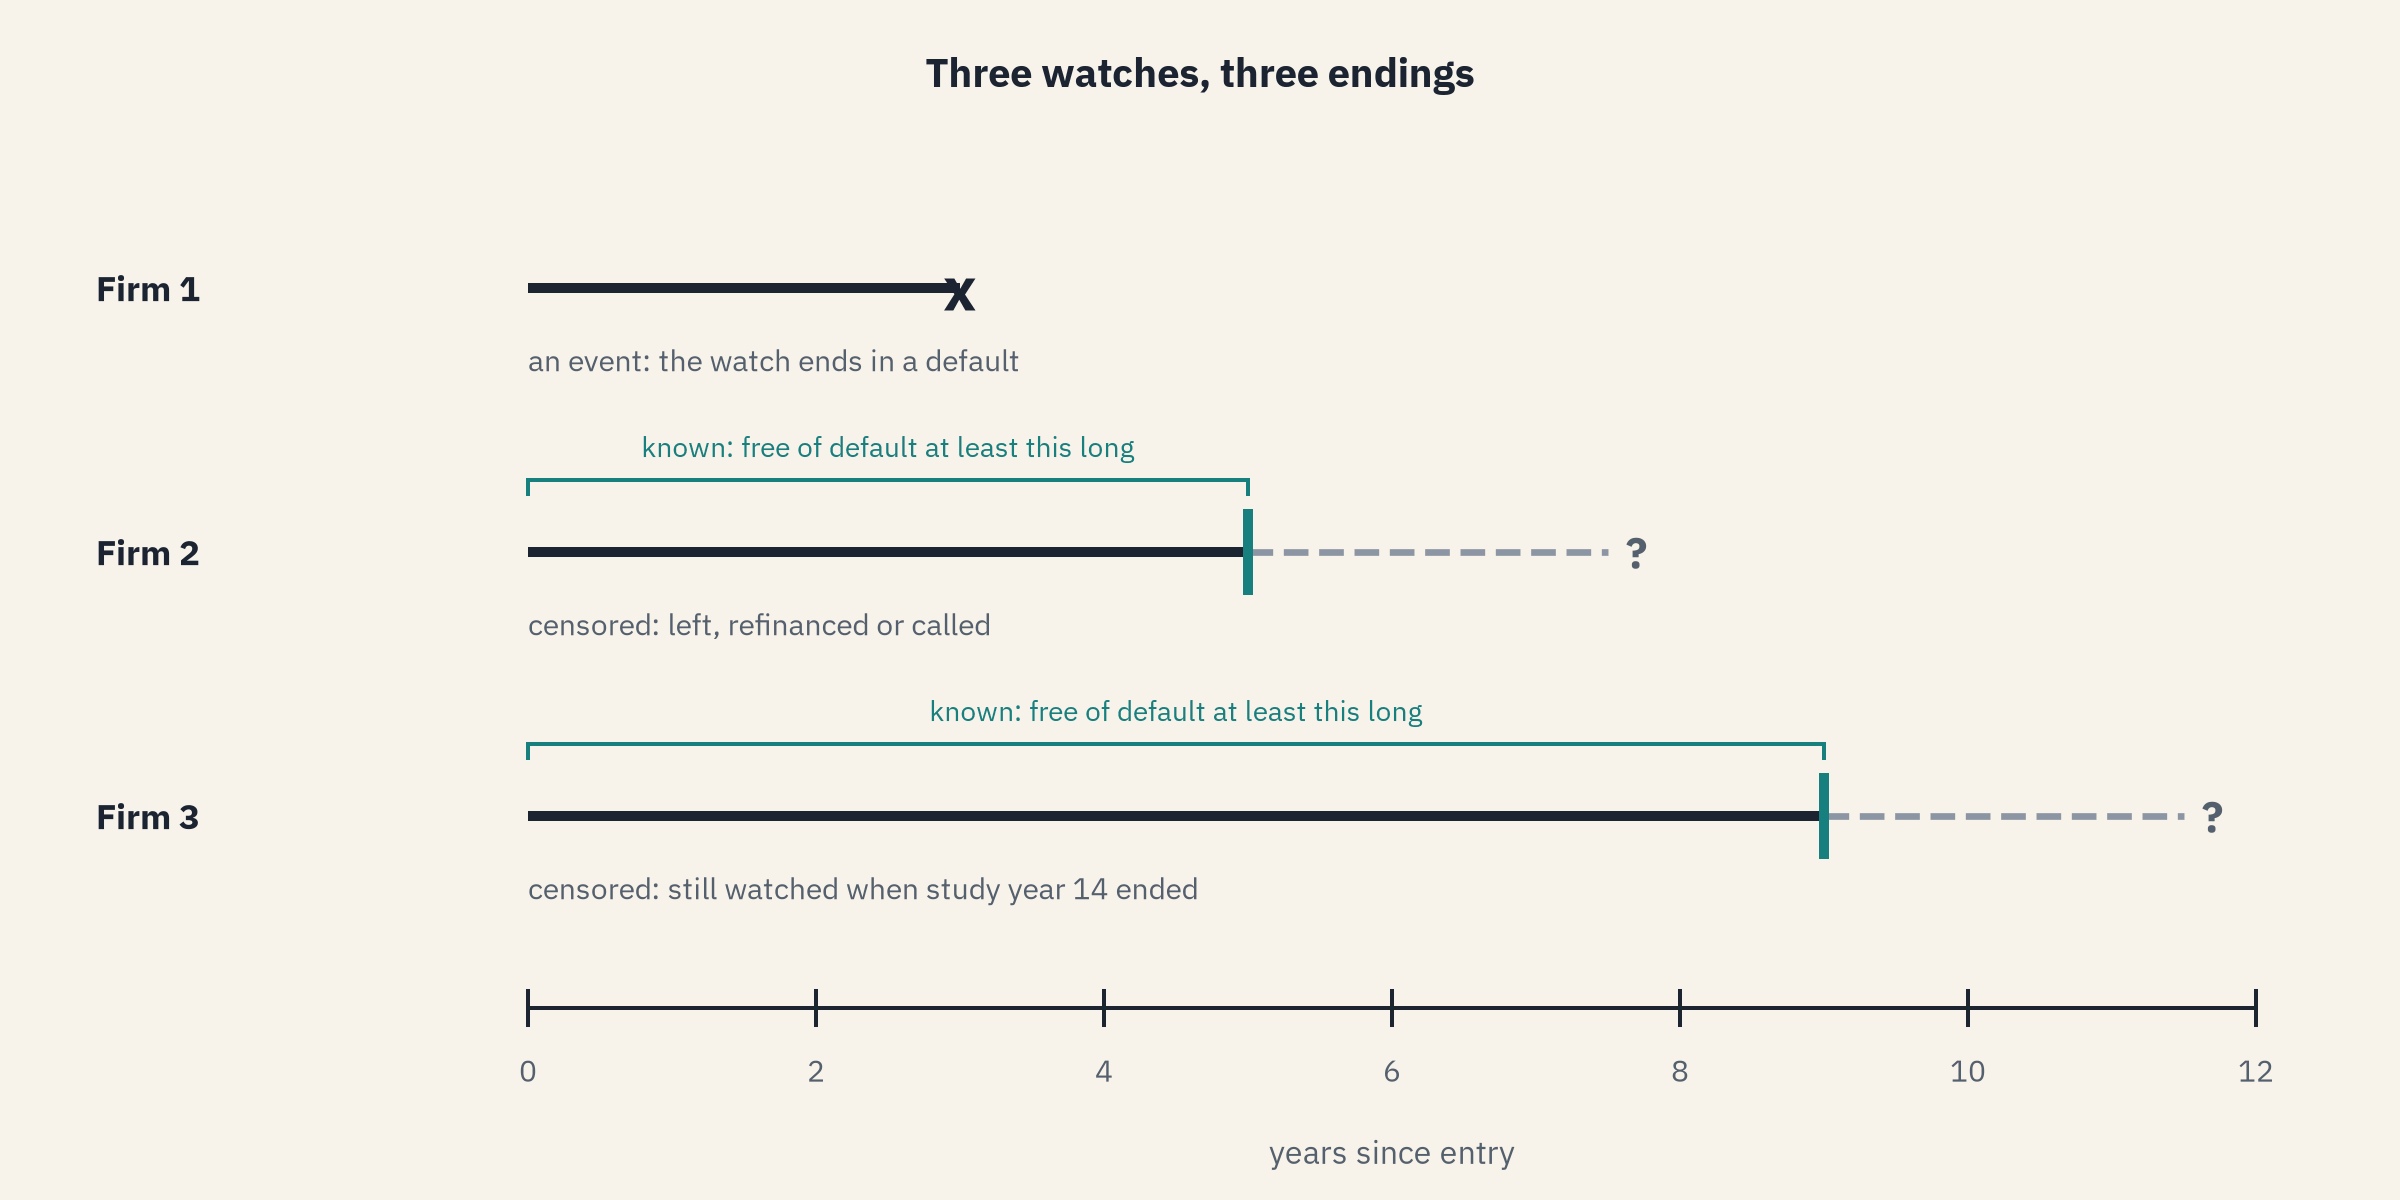)

In [7]:
# how each firm's watch ended
still = (firms["defaulted"] == 0) & (firms["exited"] == 0)
print("Defaulted:", firms["defaulted"].sum(), "| exited:", firms["exited"].sum(), "| still at risk at the end of year 14:", still.sum())
print(f"Censored: {100 * (1 - firms['defaulted'].mean()):.1f} percent of the firms")

Defaulted: 345 | exited: 1231 | still at risk at the end of year 14: 1928
Censored: 90.2 percent of the firms


## Years Watched

In [8]:
# how long the watches ran, and the firms watched from study year 1 to 14
print("Median:", firms["years"].median(), "| mean:", round(firms["years"].mean(), 2), "| watched all 14 years:", (firms["years"] == 14).sum())

Median: 4.0 | mean: 5.28 | watched all 14 years: 73


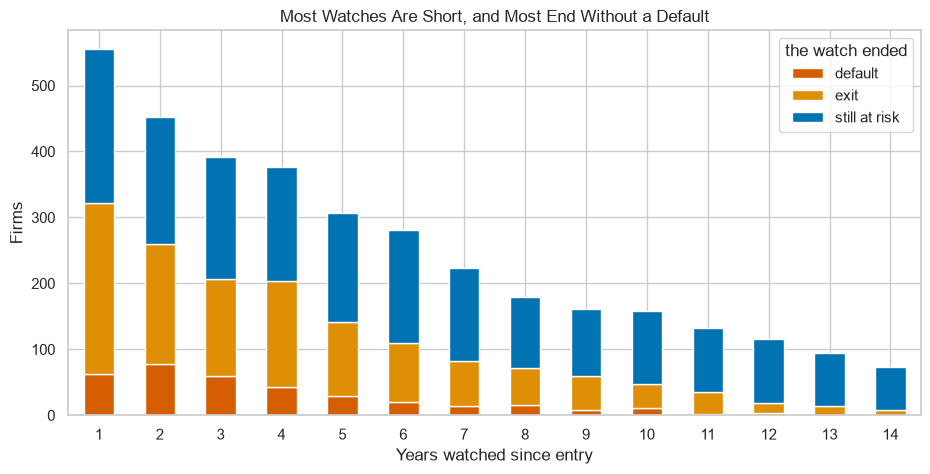

In [9]:
# firms by years watched, stacked by how the watch ended
ending = np.where(firms["defaulted"] == 1, "default", np.where(firms["exited"] == 1, "exit", "still at risk"))
by_length = pd.crosstab(firms["years"], ending)[["default", "exit", "still at risk"]]
by_length.plot(kind="bar", stacked=True, figsize=(11, 5), rot=0, color=["C3", "C1", "C0"])
plt.xlabel("Years watched since entry")
plt.ylabel("Firms")
plt.title("Most Watches Are Short, and Most End Without a Default")
plt.legend(title="the watch ended")
plt.show()

Defaults are a thin layer at every length.

Of the one-year watches, many are firms still at risk: they entered in study year 14 and the study ended.

## The Watches on One Chart

A **Lexis diagram** puts the study year across and the years since entry up: each firm is a 45-degree line from its entry to the end of its watch.

In [10]:
# 40 firms drawn at random with Course 5's rng.choice(..., replace=False), and how each watch ended
rng = np.random.default_rng(SEED)
sample = firms.loc[rng.choice(firms.index, 40, replace=False)]
print("Defaulted:", sample["defaulted"].sum(), "| exited:", sample["exited"].sum(), "| still at risk:", ((sample["defaulted"] == 0) & (sample["exited"] == 0)).sum())

Defaulted: 2 | exited: 15 | still at risk: 23


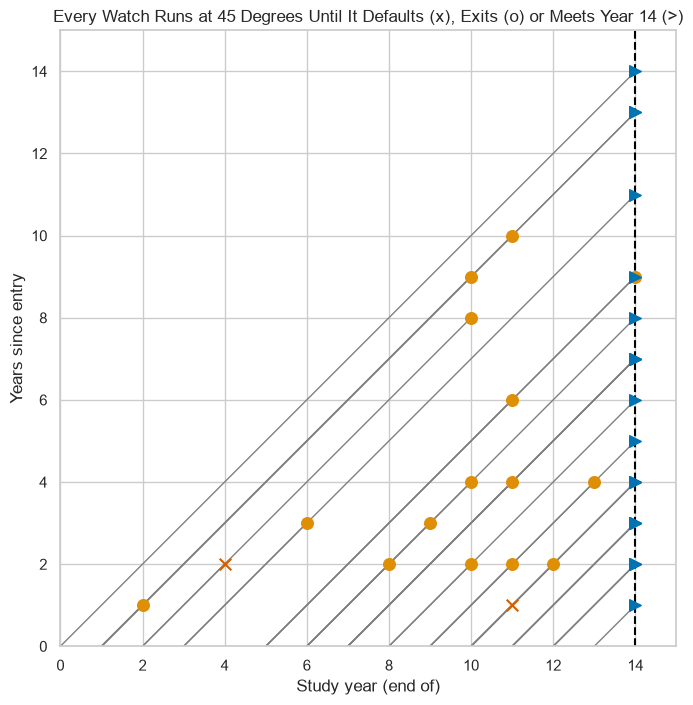

In [11]:
# each firm a line from (entry year - 1, 0) to (its last study year, years watched), its ending marked
MARKS = {(1, 0): ("x", "C3"), (0, 1): ("o", "C1"), (0, 0): (">", "C0")}
fig, ax = plt.subplots(figsize=(11, 8))
for firm in sample.itertuples():
    last = firm.entry_year - 1 + firm.years
    marker, colour = MARKS[(firm.defaulted, firm.exited)]
    ax.plot([firm.entry_year - 1, last], [0, firm.years], color="gray", linewidth=1)
    ax.scatter(last, firm.years, marker=marker, s=70, color=colour, zorder=3)
ax.axvline(DEVELOPMENT_END, color="black", linestyle="--")
# Day 3's set_aspect("equal"): a study year and a year since entry take the same length, so each line runs at 45 degrees
ax.set_aspect("equal")
ax.set(xlim=(0, 15), ylim=(0, 15), xlabel="Study year (end of)", ylabel="Years since entry",
       title="Every Watch Runs at 45 Degrees Until It Defaults (x), Exits (o) or Meets Year 14 (>)")
plt.show()

The 40 are drawn at random: the file's one default in ten gives about 4 in 40, and 2 is well within chance of that.

Firms that entered in the same study year run along one line, so the 40 show as fewer lines.

The year-14 line cuts every late entrant short: a firm that entered in year 12 can show at most 3 years.

**Nine firms in ten end their watch without a default; a curve that throws them away throws away most of the file.**

# Kaplan-Meier by Hand

## Ten Firms

The ten are 3 firms drawn from those that defaulted and 7 from the rest: a split chosen for the lesson, so the hand table has defaults.

In [12]:
# 3 defaulted firms, then 7 others, from one generator, sorted by years watched
rng = np.random.default_rng(SEED)
picked = list(rng.choice(firms.index[firms["defaulted"] == 1], 3, replace=False)) + list(rng.choice(firms.index[firms["defaulted"] == 0], 7, replace=False))
ten = firms.loc[picked, ["years", "defaulted", "exited"]].sort_values(["years", "defaulted"], ascending=[True, False])
ten

,years,defaulted,exited
firm_id,,,
F3024,1,0,1
F0313,1,0,1
F3422,1,0,0
F0340,1,0,1
F1882,3,1,0
F0248,3,1,0
F2238,5,1,0
F2479,5,0,0
F1889,7,0,0


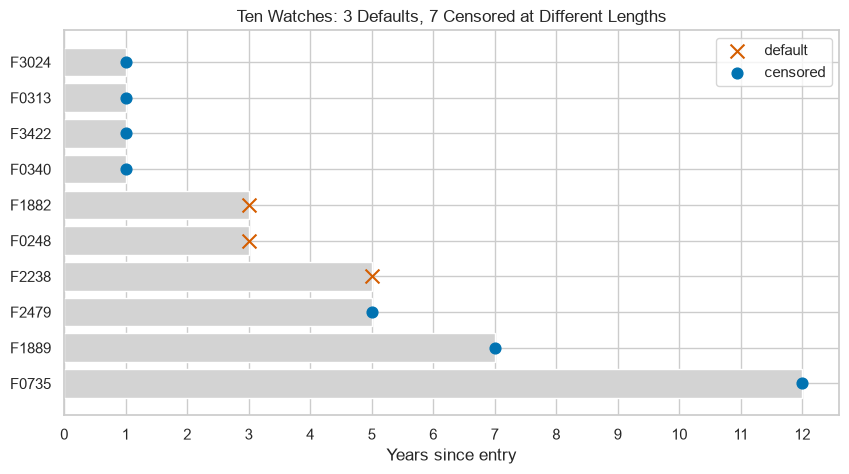

In [13]:
# a swimmer plot: one bar per firm from its entry, x where the watch ended in a default, o where it was censored
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(ten.index, ten["years"], color="lightgray")
ax.scatter(ten["years"][ten["defaulted"] == 1], ten.index[ten["defaulted"] == 1], marker="x", s=100, color="C3", zorder=3, label="default")
ax.scatter(ten["years"][ten["defaulted"] == 0], ten.index[ten["defaulted"] == 0], marker="o", s=60, color="C0", zorder=3, label="censored")
ax.invert_yaxis()
ax.set(xlabel="Years since entry", xticks=range(0, 13), title="Ten Watches: 3 Defaults, 7 Censored at Different Lengths")
ax.legend()
plt.show()

The **survival function** S(t) is the share free of default past t years.
A firm is **at risk** in year t if it was watched at least t years.
In each year with a default, the share of firms at risk that came through is 1 less defaults over at risk.
S(t) is the **running product** of those shares, so a censored firm counts while it is watched and then leaves the count.

**Predict 1**

7 of the 10 never defaulted, so counting every firm to the end gives 0.7.

Q. What does the running product give past 12 years? Write down a number.

## The Running Product

In [14]:
# at each distinct year: firms at risk, defaults, censored, and the running product
rows = []
running = 1.0
for t in sorted(ten["years"].unique()):
    at_risk = (ten["years"] >= t).sum()
    defaults = ((ten["years"] == t) & (ten["defaulted"] == 1)).sum()
    running = running * (1 - defaults / at_risk)
    rows.append({"year": t, "at risk": at_risk, "defaults": defaults, "censored": ((ten["years"] == t) & (ten["defaulted"] == 0)).sum(), "survival": running})
hand = pd.DataFrame(rows).set_index("year")
hand.round(4)

,at risk,defaults,censored,survival
year,,,,
1,10,0,4,1.0000
3,6,2,0,0.6667
5,4,1,1,0.5000
7,2,0,1,0.5000
12,1,0,1,0.5000


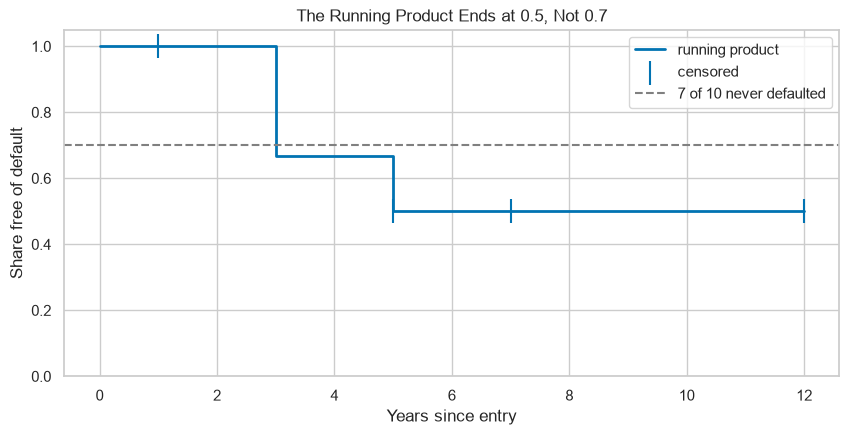

In [15]:
# the running product as steps, a tick where a firm was censored, and the 0.7 that counts every firm to the end
censored_years = hand.index[hand["censored"] > 0]
plt.figure(figsize=(10, 4.5))
plt.step([0] + list(hand.index), [1] + list(hand["survival"]), where="post", linewidth=2, label="running product")
plt.scatter(censored_years, hand.loc[censored_years, "survival"], marker="|", s=300, color="C0", label="censored")
plt.axhline(0.7, color="gray", linestyle="--", label="7 of 10 never defaulted")
plt.ylim(0, 1.05)
plt.xlabel("Years since entry")
plt.ylabel("Share free of default")
plt.title("The Running Product Ends at 0.5, Not 0.7")
plt.legend()
plt.show()

At year 3 two of 6 at risk defaulted: S fell to 1 times 4/6.

The four firms censored at year 1 left the count without lowering S.

## The Same Steps as a Function

**Kaplan-Meier** is this running product, written once for any list of watches.
`np.unique` lists the distinct times (Course 5), and `np.cumprod` multiplies a running product as `np.cumsum` adds a running sum.

In [16]:
# Kaplan-Meier: at risk, events and the running product at each distinct time
def kaplan_meier(time, event):
    """At risk, events and the running product at each distinct time."""
    times = np.unique(time)
    at_risk = np.array([(time >= t).sum() for t in times])
    events = np.array([((time == t) & (event == 1)).sum() for t in times])
    return pd.DataFrame({"at_risk": at_risk, "events": events, "survival": np.cumprod(1 - events / at_risk)}, index=times)

kaplan_meier(ten["years"], ten["defaulted"]).round(4)

,at_risk,events,survival
1,10,0,1.0000
3,6,2,0.6667
5,4,1,0.5000
7,2,0,0.5000
12,1,0,0.5000


**Four lines turn any list of watches into a curve; next, the cohort, and the shortcuts it is tempting to take.**

# Three Ways to Treat a Censored Firm

## The Cohort's Curve, Kaplan-Meier

In [17]:
# Kaplan-Meier on all 3,504 firms, read past 1, 5, 10 and 14 years
km = kaplan_meier(firms["years"], firms["defaulted"])
km.loc[[1, 5, 10, 14]].round(4)

,at_risk,events,survival
1,3504,62,0.9823
5,1727,29,0.8996
10,574,11,0.8359
14,73,1,0.8070


Past 10 years Kaplan-Meier leaves 0.8359 of the firms free of default, on 574 still watched.

**Predict 2**

Kaplan-Meier gives 0.8070 past 14 years.

Q. Drop every firm censored before year 14: of the firms left, what share is free of default past 14 years? Write down a percent.

## Dropping Them, or Counting Them as Survivors

Two shortcuts, each 1 less the defaults by year t over a count of firms:

* **dropping** divides by the firms that defaulted by t or were watched at least t years
* **counting them as survivors** divides by every firm

In [18]:
# defaults by each year, the firms each shortcut divides by, and the three curves side by side
YEARS = np.arange(1, 15)
defaults_by = np.array([((firms["defaulted"] == 1) & (firms["years"] <= t)).sum() for t in YEARS])
kept = np.array([((firms["defaulted"] == 1) | (firms["years"] >= t)).sum() for t in YEARS])
three = pd.DataFrame({"dropped": 1 - defaults_by / kept, "survivors": 1 - defaults_by / len(firms), "Kaplan-Meier": km["survival"]}, index=YEARS)
print("Firms kept by dropping at year 14:", kept[-1], "| censored before year 14 and dropped:", len(firms) - kept[-1])
three.loc[[5, 10, 14]].round(4)

Firms kept by dropping at year 14: 417 | censored before year 14 and dropped: 3087


,dropped,survivors,Kaplan-Meier
5,0.8628,0.9229,0.8996
10,0.6249,0.9035,0.8359
14,0.1727,0.9015,0.8070


A **number-at-risk table** lists, at chosen years, the firms still watched and the firms censored so far; set under a survival curve it shows what each step rests on.

In [19]:
# the number-at-risk table at every second year
TICKS = np.arange(0, 15, 2)
risk_table = pd.DataFrame({"at risk": [(firms["years"] >= t).sum() for t in TICKS],
                           "censored so far": [((firms["defaulted"] == 0) & (firms["years"] < t)).sum() for t in TICKS]}, index=TICKS).T
risk_table

,0,2,4,6,8,10,12,14
at risk,3504,2948,2104,1420,915,574,284,73
censored so far,0,494,1202,1814,2285,2603,2880,3087


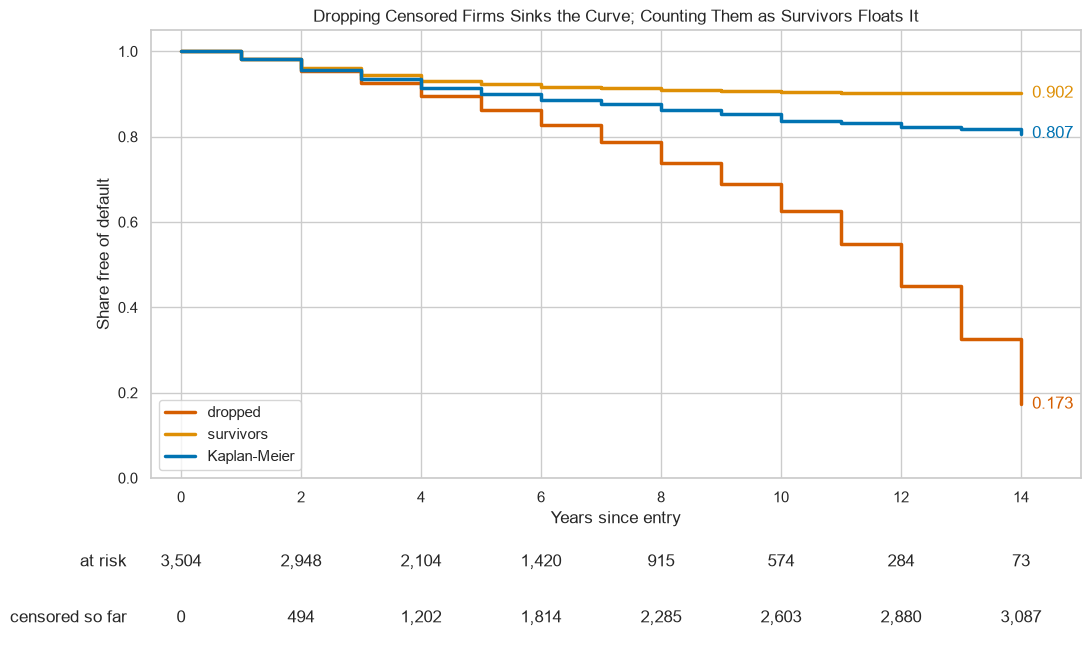

In [20]:
# the showpiece: the three curves, and the number-at-risk table aligned beneath them
fig, (top, table) = plt.subplots(2, 1, figsize=(12, 8), height_ratios=[4, 1])
# np.append(0, YEARS) puts year 0 in front, where every curve starts at 1
for name, colour in [("dropped", "C3"), ("survivors", "C1"), ("Kaplan-Meier", "C0")]:
    top.step(np.append(0, YEARS), np.append(1, three[name]), where="post", linewidth=2.5, color=colour, label=name)
    top.annotate(f"{three.loc[14, name]:.3f}", (14, three.loc[14, name]), xytext=(8, 0), textcoords="offset points", va="center", color=colour)
top.set(xlim=(-0.5, 15), xticks=TICKS, xlabel="Years since entry", ylabel="Share free of default", ylim=(0, 1.05),
        title="Dropping Censored Firms Sinks the Curve; Counting Them as Survivors Floats It")
top.legend(loc="lower left")
for row, label in enumerate(risk_table.index):
    table.text(-0.9, 1 - row, label, ha="right", va="center")
    for t in TICKS:
        table.text(t, 1 - row, f"{risk_table.loc[label, t]:,}", ha="center", va="center")
table.set(ylim=(-0.5, 1.5), xlim=(-0.5, 15))
table.set_axis_off()
plt.show()

Dropping keeps every default and loses only firms that were free of default when last seen, so it sinks the curve: past 14 years it rests on 417 firms, 345 of them defaults.

Counting the censored as survivors credits them with years nobody saw, so it floats the curve.

Kaplan-Meier assumes a censored firm had the same chance of default each year as the firms still watched; the file's exits meet it by construction, 7 percent a year unrelated to default (`DATA.md`).

**Both shortcuts miss by far more than any sampling error: censoring is counted for the years watched, never dropped.**

> STORY: Edward Kaplan studied how long vacuum tubes lasted in telephone cables under the ocean; Paul Meier had met the problem in Greenwood's paper on the duration of cancer.
> Both sent manuscripts to the Journal of the American Statistical Association, which recommended one joint paper, and Kaplan later recalled that it took much correspondence over four years to reconcile their approaches.
> "Nonparametric Estimation from Incomplete Observations" appeared in June 1958, and by November 2017 it had 44,319 Web of Science citations.
> The article that tells the story notes that Greenwood had already seen, in 1926, that dropping living patients watched for less than the whole study set a survival estimate too low, and counting them alive to its end set it too high.
> Sources: L. J. A. Stalpers and E. L. Kaplan, "Edward L. Kaplan and the Kaplan-Meier Survival Curve", BSHM Bulletin 33 (2), 2018, pages 109 to 111, https://doi.org/10.1080/17498430.2018.1450055 (Kaplan quoted from Garfield, Current Contents, 1983); E. L. Kaplan and P. Meier, Journal of the American Statistical Association 53 (282), 1958, pages 457 to 481, https://doi.org/10.1080/01621459.1958.10501452

# The Cohort's Curve with statsmodels

## SurvfuncRight

statsmodels' `SurvfuncRight(time, event)` fits the same curve.
Its `.surv_times`, `.surv_prob`, `.surv_prob_se` and `.n_risk` hold each time with a default, the curve, its standard error and the firms at risk; `.summary()` sets them in one table.

In [21]:
# the cohort's curve from statsmodels, and its largest gap to kaplan_meier
curve = SurvfuncRight(firms["years"], firms["defaulted"])
print(f"Largest gap to kaplan_meier: {np.abs(curve.surv_prob - km['survival'].to_numpy()).max():.1e}")
curve.summary().loc[[1, 5, 10, 14], ["Surv prob", "Surv prob SE", "num at risk"]].round(4)

Largest gap to kaplan_meier: 1.1e-16


,Surv prob,Surv prob SE,num at risk
Time,,,
1,0.9823,0.0022,3504
5,0.8996,0.0059,1727
10,0.8359,0.0096,574
14,0.8070,0.0163,73


`.surv_times` holds only the times with a default, so a group with none, AA or AAA at entry, has an empty curve.

## Greenwood's Band

**Greenwood's standard error** is S times the square root of the running sum of d / (n (n - d)), with d the year's defaults and n the firms at risk.

In [22]:
# Greenwood's standard error by hand, against statsmodels' surv_prob_se
greenwood = km["survival"] * np.sqrt(np.cumsum(km["events"] / (km["at_risk"] * (km["at_risk"] - km["events"]))))
print(f"Largest gap to surv_prob_se: {np.abs(greenwood.to_numpy() - curve.surv_prob_se).max():.1e}")

Largest gap to surv_prob_se: 1.7e-18


The band's setting is its multiplier: 1.96 for 95 percent (Course 4's Day 3), `stats.norm.ppf(0.995)` for 99 (Day 1's `ppf`).

In [23]:
# the band at year 14 at each level
for level, multiplier in [(95, 1.96), (99, stats.norm.ppf(0.995))]:
    print(f"{level} percent, multiplier {multiplier:.3f}: {curve.surv_prob[-1] - multiplier * curve.surv_prob_se[-1]:.4f} to {curve.surv_prob[-1] + multiplier * curve.surv_prob_se[-1]:.4f}")

95 percent, multiplier 1.960: 0.7751 to 0.8389
99 percent, multiplier 2.576: 0.7651 to 0.8490


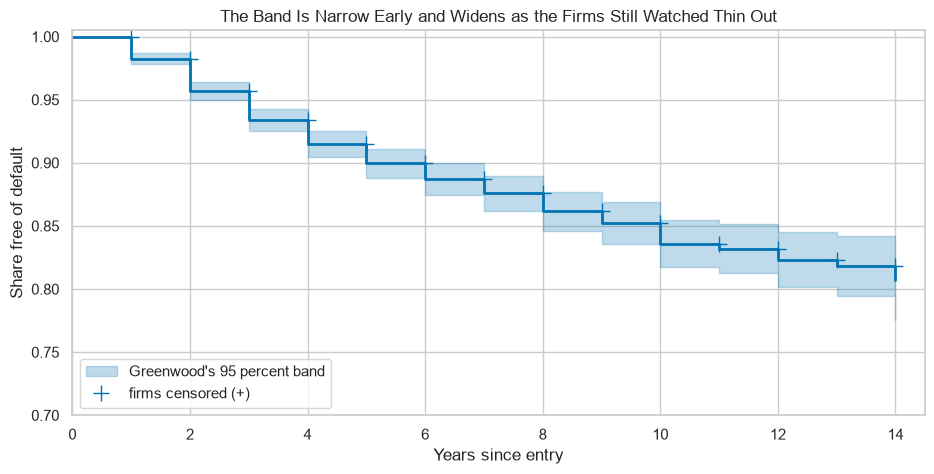

In [24]:
# statsmodels draws the steps and a + where firms were censored; the 95 percent band drawn as steps beneath
times = np.append(0, curve.surv_times)
# a share cannot pass 1 or fall below 0, so np.clip holds the band inside them
low = np.clip(np.append(1, curve.surv_prob - 1.96 * curve.surv_prob_se), 0, 1)
high = np.clip(np.append(1, curve.surv_prob + 1.96 * curve.surv_prob_se), 0, 1)
fig, ax = plt.subplots(figsize=(11, 5))
band = ax.fill_between(times, low, high, step="post", color="C0", alpha=0.25)
curve.plot(ax=ax)
ax.set(xlim=(0, 14.5), ylim=(0.7, 1.005), xlabel="Years since entry", ylabel="Share free of default", title="The Band Is Narrow Early and Widens as the Firms Still Watched Thin Out")
# ax.get_lines() lists the lines drawn on ax: statsmodels' second is its + marks, so the legend takes it and the band by hand
ax.legend([band, ax.get_lines()[1]], ["Greenwood's 95 percent band", "firms censored (+)"], loc="lower left")
plt.show()

The band holds at each year on its own, not for the whole curve at once.

Its last step rests on 73 firms, and the band is widest there.

**The curve is sure early and loose late: read its last years with their band.**

# Curves by Rating at Entry

## Four Groups

AAA to BBB are pooled as investment grade for the curves: AAA and AA entrants counted no default, and A entrants 2.

In [25]:
# firms and defaults in each group at entry
ORDER = ["IG", "BB", "B", "CCC"]
firms.groupby("group").agg(firms=("defaulted", "size"), defaults=("defaulted", "sum")).loc[ORDER]

,firms,defaults
group,,
IG,1583,15
BB,965,69
B,721,149
CCC,235,112


**Predict 3**

Day 3 counted 14.86 percent a year for CCC firm-years.
Held for five years as a running product with every year's factor the same, `(1 - 0.1486) ** 5`, it leaves 44.7 percent.

Q. What share of the CCC entrants does Kaplan-Meier leave free of default past 5 years? Write down a percent.

## One Curve per Group

In [26]:
# each group's Kaplan-Meier curve, read past 3, 5 and 10 years
group_km = {name: kaplan_meier(firms.loc[firms["group"] == name, "years"], firms.loc[firms["group"] == name, "defaulted"]) for name in ORDER}
reading = pd.DataFrame({name: group_table["survival"].loc[[3, 5, 10]] for name, group_table in group_km.items()}).T
reading.columns = ["past 3", "past 5", "past 10"]
reading.round(4)

,past 3,past 5,past 10
IG,0.9951,0.9914,0.9849
BB,0.9651,0.9316,0.8690
B,0.8668,0.7787,0.5842
CCC,0.5508,0.3957,0.2117


The CCC entrants' curve leaves 39.6 percent past 5 years, below the 44.7 that 14.86 percent a year gives.

The curve follows CCC entrants, whose ratings move after entry, while 14.86 counts the years spent at CCC.

In [27]:
# each group's curve from statsmodels, for its band, and the group's firms at risk at every second year
group_fits = {name: SurvfuncRight(firms.loc[firms["group"] == name, "years"], firms.loc[firms["group"] == name, "defaulted"]) for name in ORDER}
group_at_risk = pd.DataFrame({name: [(firms.loc[firms["group"] == name, "years"] >= t).sum() for t in TICKS] for name in ORDER}, index=TICKS).T
group_at_risk

,0,2,4,6,8,10,12,14
IG,1583,1398,1093,766,508,327,163,47
BB,965,814,596,411,261,167,80,20
B,721,573,348,211,131,71,34,6
CCC,235,163,67,32,15,9,7,0


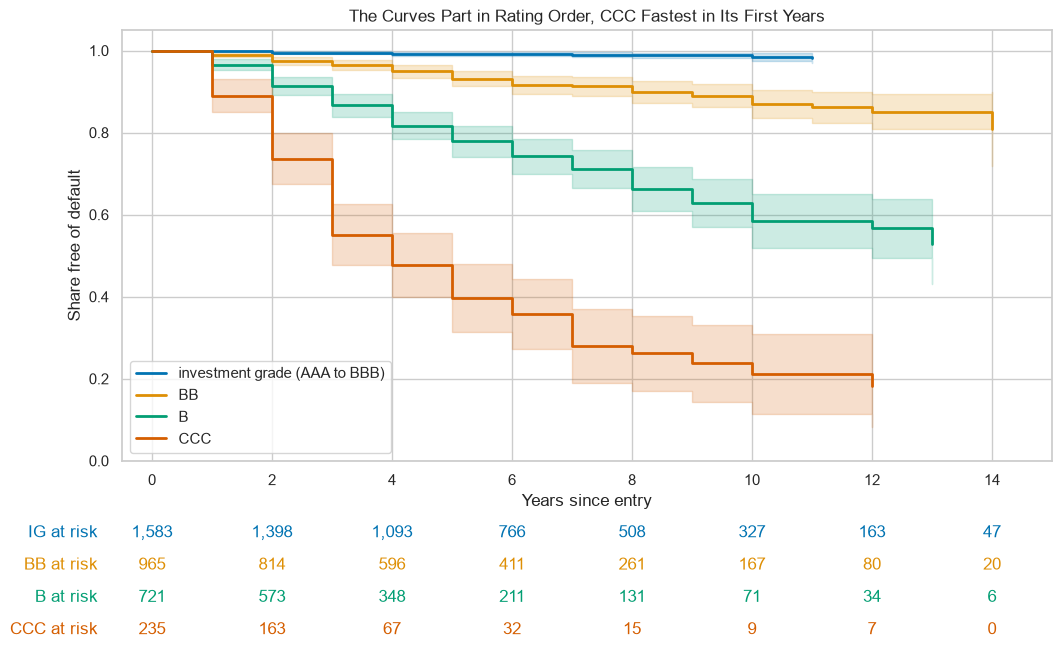

In [28]:
# the four curves with their 95 percent bands, and the number-at-risk table beneath
fig, (top, table) = plt.subplots(2, 1, figsize=(12, 8), height_ratios=[4, 1.2])
for i, (name, fit) in enumerate(group_fits.items()):
    top.step(np.append(0, fit.surv_times), np.append(1, fit.surv_prob), where="post", linewidth=2, color=f"C{i}", label="investment grade (AAA to BBB)" if name == "IG" else name)
    top.fill_between(np.append(0, fit.surv_times), np.clip(np.append(1, fit.surv_prob - 1.96 * fit.surv_prob_se), 0, 1),
                     np.clip(np.append(1, fit.surv_prob + 1.96 * fit.surv_prob_se), 0, 1), step="post", color=f"C{i}", alpha=0.2)
    table.text(-0.9, 3 - i, f"{name} at risk", ha="right", va="center", color=f"C{i}")
    for t in TICKS:
        table.text(t, 3 - i, f"{group_at_risk.loc[name, t]:,}", ha="center", va="center", color=f"C{i}")
top.set(xlim=(-0.5, 15), xticks=TICKS, xlabel="Years since entry", ylabel="Share free of default", ylim=(0, 1.05),
        title="The Curves Part in Rating Order, CCC Fastest in Its First Years")
top.legend(loc="lower left")
table.set(ylim=(-0.5, 3.5), xlim=(-0.5, 15))
table.set_axis_off()
plt.show()

The CCC curve falls fastest in its first three years.

The investment grade band is narrow because 1,583 firms are watched, though only 15 defaulted; CCC's is wide where its last 9 firms are watched at year 10.

**The curves part in rating order; next, a test of whether a gap is more than chance.**

# The Log-Rank Test

## Defaults Against a Shared Curve

If every group shared one curve, each year's defaults would fall on the groups in proportion to the firms each had at risk.

In [29]:
# each year's defaults shared out by each group's share of the firms at risk, summed over the years
shared = pd.Series(0.0, index=ORDER)
for t in km.index:
    watched = firms[firms["years"] >= t]
    year_defaults = ((watched["years"] == t) & (watched["defaulted"] == 1)).sum()
    shared = shared + year_defaults * pd.Series({name: (watched["group"] == name).mean() for name in ORDER})
counted = pd.DataFrame({"observed": firms.groupby("group")["defaulted"].sum().loc[ORDER], "under a shared curve": shared})
counted.round(1)

,observed,under a shared curve
IG,15,173.5
BB,69,96.6
B,149,60.3
CCC,112,14.7


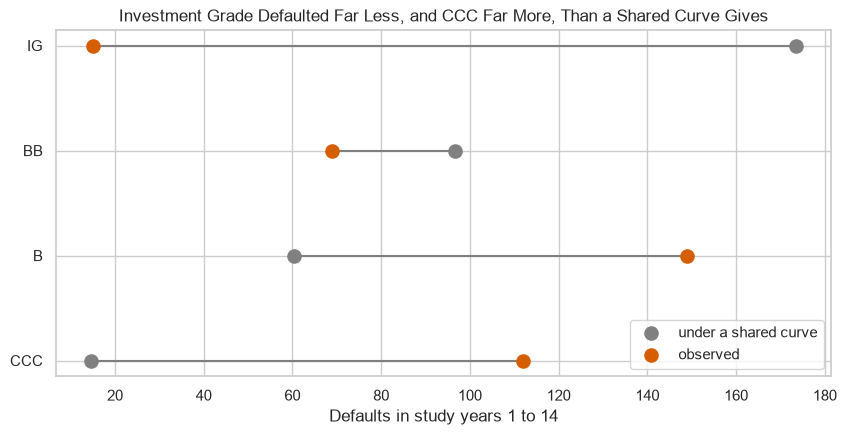

In [30]:
# a dumbbell: observed defaults against the count a shared curve gives, one row per group
plt.figure(figsize=(10, 4.5))
for i, name in enumerate(ORDER):
    plt.plot(counted.loc[name], [i, i], color="gray", zorder=1)
plt.scatter(counted["under a shared curve"], range(4), s=90, color="gray", zorder=2, label="under a shared curve")
plt.scatter(counted["observed"], range(4), s=90, color="C3", zorder=3, label="observed")
plt.yticks(range(4), ORDER)
plt.gca().invert_yaxis()
plt.xlabel("Defaults in study years 1 to 14")
plt.title("Investment Grade Defaulted Far Less, and CCC Far More, Than a Shared Curve Gives")
plt.legend()
plt.show()

The **log-rank test** sums those gaps, year by year, into a chi-squared statistic with the groups less one degrees of freedom (Course 5B's Day 4).

## Running the Test

`survdiff(time, event, group)` returns the statistic and its p-value; its p-value reads 0.0 once it falls below about 1e-16, so the p-value here comes from `stats.chi2.sf` (Day 2).

In [31]:
# the log-rank test across the four groups
statistic = survdiff(firms["years"], firms["defaulted"], firms["group"])[0]
print(f"Chi-squared {statistic:.1f} on 3 degrees of freedom | p-value {stats.chi2.sf(statistic, 3):.0e}, below 1e-16")

Chi-squared 960.8 on 3 degrees of freedom | p-value 6e-208, below 1e-16


In [32]:
# neighbouring buckets at entry, two at a time: a p-value below 0.0001 printed in the .0e format
pair_rows = []
for upper, lower in [("BB", "B"), ("BBB", "BB"), ("A", "BBB"), ("AA", "A")]:
    pair = firms[firms["entry_bucket"].isin([upper, lower])]
    pair_statistic = survdiff(pair["years"], pair["defaulted"], pair["entry_bucket"])[0]
    p_value = stats.chi2.sf(pair_statistic, 1)
    pair_rows.append({"pair": f"{upper} against {lower}", "firms": len(pair), "defaults": pair["defaulted"].sum(),
                      "chi-squared": round(pair_statistic, 2), "p-value": f"{p_value:.0e}" if p_value < 0.0001 else f"{p_value:.4f}"})
pairs = pd.DataFrame(pair_rows).set_index("pair")
pairs

,firms,defaults,chi-squared,p-value
pair,,,,
BB against B,1686,218,90.70,2e-21
BBB against BB,1843,82,36.14,2e-09
A against BBB,1353,15,3.67,0.0555
AA against A,680,2,0.86,0.3538


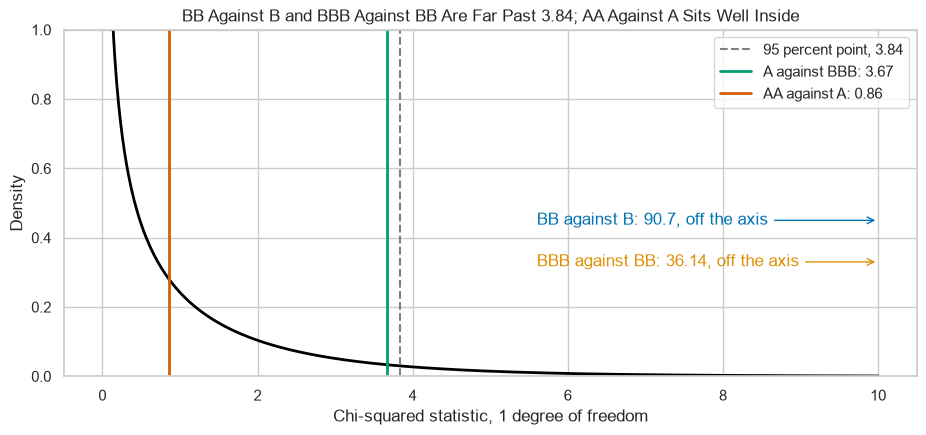

In [33]:
# the chi-squared density on 1 degree of freedom (stats.chi2.pdf, as Course 4's stats.norm.pdf), its 95 percent point, and each pair's statistic
x = np.linspace(0.01, 10, 400)
plt.figure(figsize=(11, 4.5))
plt.plot(x, stats.chi2.pdf(x, 1), color="black", linewidth=2)
plt.axvline(stats.chi2.ppf(0.95, 1), color="gray", linestyle="--", label="95 percent point, 3.84")
for i, (name, row) in enumerate(pairs.iterrows()):
    if row["chi-squared"] <= 10:
        plt.axvline(row["chi-squared"], color=f"C{i}", linewidth=2, label=f"{name}: {row['chi-squared']}")
    else:
        plt.annotate(f"{name}: {row['chi-squared']}, off the axis", xy=(10, 0.45 - 0.12 * i), xytext=(5.6, 0.45 - 0.12 * i), va="center", color=f"C{i}", arrowprops={"arrowstyle": "->", "color": f"C{i}"})
plt.ylim(0, 1)
plt.xlabel("Chi-squared statistic, 1 degree of freedom")
plt.ylabel("Density")
plt.title("BB Against B and BBB Against BB Are Far Past 3.84; AA Against A Sits Well Inside")
plt.legend(loc="upper right")
plt.show()

### Interpretation of the P-Values

The four groups, BB against B and BBB against BB: the gaps between the curves are more than chance in this file.

A against BBB rests on 15 defaults and sits just above 0.05.

AA against A rests on 2 defaults, both A's: no evidence of a difference is not evidence of none, Day 3's low-default problem in a test's words.

A rating at entry goes with a steeper curve; the test says nothing of why.

**The test sees only what the defaults let it see.**

# The Hazard

## The Hazard Year by Year

The **hazard** in year t is the year's defaults over the firms at risk, in percent a year: the counted default rate of these invented firms in their t-th year since entry.

In [34]:
# the hazard each year since entry, with Course 5's Day 2 binomial spread for a 1.96 whisker
hazard = km[["at_risk", "events"]].copy()
hazard["hazard_pct"] = 100 * hazard["events"] / hazard["at_risk"]
hazard["whisker_pct"] = 1.96 * np.sqrt(hazard["hazard_pct"] * (100 - hazard["hazard_pct"]) / hazard["at_risk"])
hazard.round(2)

,at_risk,events,hazard_pct,whisker_pct
1,3504,62,1.77,0.44
2,2948,77,2.61,0.58
3,2496,59,2.36,0.60
4,2104,43,2.04,0.60
5,1727,29,1.68,0.61
6,1420,20,1.41,0.61
7,1139,14,1.23,0.64
8,915,15,1.64,0.82
9,735,8,1.09,0.75
10,574,11,1.92,1.12


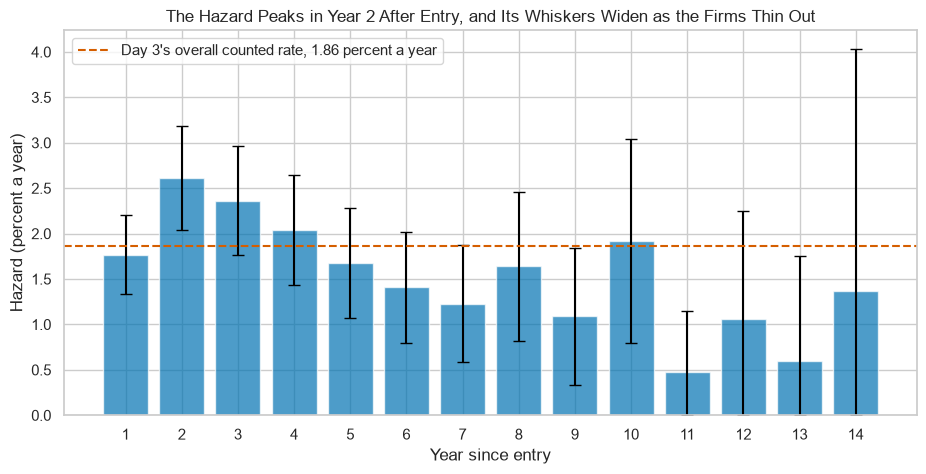

In [35]:
# the yearly hazard as bars, whiskers clipped at 0 (fmt="none" draws the whiskers alone), and Day 3's overall counted rate dashed
low_whisker = hazard["hazard_pct"] - (hazard["hazard_pct"] - hazard["whisker_pct"]).clip(lower=0)
plt.figure(figsize=(11, 5))
plt.bar(hazard.index, hazard["hazard_pct"], color="C0", alpha=0.7)
plt.errorbar(hazard.index, hazard["hazard_pct"], yerr=[low_whisker, hazard["whisker_pct"]], fmt="none", color="black", capsize=4)
plt.axhline(1.86, color="C3", linestyle="--", label="Day 3's overall counted rate, 1.86 percent a year")
plt.xticks(hazard.index)
plt.xlabel("Year since entry")
plt.ylabel("Hazard (percent a year)")
plt.title("The Hazard Peaks in Year 2 After Entry, and Its Whiskers Widen as the Firms Thin Out")
plt.legend()
plt.show()

The generator raises the chance of default in years 2 to 4 after entry (`DATA.md`), and the bars show it; the file does not record why.

The normal whisker is rough where defaults are few, years 11 to 14 on 416 to 73 firms: Day 3's low-default problem again.

## The Cumulative Hazard

The **cumulative hazard** adds the yearly hazards; as a running sum of defaults over at risk it is the **Nelson-Aalen** estimate.
While hazards are small it sits close to minus the log of the Kaplan-Meier curve.

In [36]:
# Nelson-Aalen, the running sum of the hazards, beside minus the log of the Kaplan-Meier curve
cumulative = pd.DataFrame({"Nelson-Aalen": np.cumsum(km["events"] / km["at_risk"]), "minus log of S": -np.log(km["survival"])})
cumulative.loc[[1, 5, 10, 14]].round(4)

,Nelson-Aalen,minus log of S
1,0.0177,0.0179
5,0.1047,0.1058
10,0.1775,0.1792
14,0.2125,0.2144


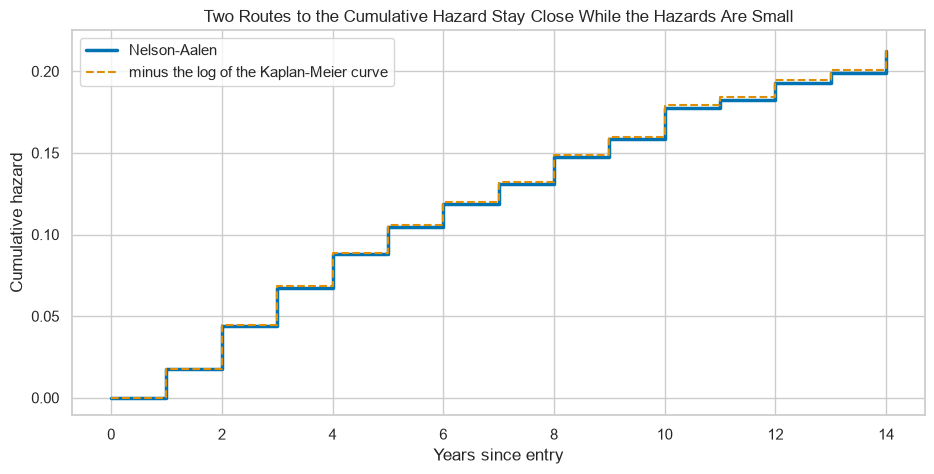

In [37]:
# the two as steps over the years since entry
plt.figure(figsize=(11, 5))
plt.step(np.append(0, cumulative.index), np.append(0, cumulative["Nelson-Aalen"]), where="post", linewidth=2.5, label="Nelson-Aalen")
plt.step(np.append(0, cumulative.index), np.append(0, cumulative["minus log of S"]), where="post", linewidth=1.5, linestyle="--", label="minus the log of the Kaplan-Meier curve")
plt.xlabel("Years since entry")
plt.ylabel("Cumulative hazard")
plt.title("Two Routes to the Cumulative Hazard Stay Close While the Hazards Are Small")
plt.legend()
plt.show()

At year 10 the two read 0.1775 and 0.1792; the gap grows as the sum does.

## A Flat Hazard

A **flat hazard** is one h for every year: all defaults over all firm-years watched.
Under it the share free of default past t years is exp(-h t), with Course 1's `np.exp`.

In [38]:
# one hazard for every year: all defaults over all firm-years watched
flat_h = firms["defaulted"].sum() / firms["years"].sum()
print(f"Flat hazard: {firms['defaulted'].sum()} / {firms['years'].sum():,} = {100 * flat_h:.4f} percent a year")

Flat hazard: 345 / 18,503 = 1.8646 percent a year


It is Day 3's overall counted rate: the same defaults over the same firm-years.

**Predict 4**

Q. Sketch exp(-h t) over 14 years beside the Kaplan-Meier curve: in which years does the flat curve sit above, where below, and by how much at year 14?

## The Flat Curve Against Kaplan-Meier

In [39]:
# the flat curve and Kaplan-Meier at each year since entry, and the gap between them
flat = pd.DataFrame({"flat": np.exp(-flat_h * km.index), "Kaplan-Meier": km["survival"]}, index=km.index)
flat["flat less Kaplan-Meier"] = flat["flat"] - flat["Kaplan-Meier"]
print(f"At year 14, (1 - h) ** 14: {(1 - flat_h) ** 14:.4f} | exp(-14 h): {np.exp(-14 * flat_h):.4f}")
flat.loc[[1, 2, 4, 7, 8, 10, 14]].round(4)

At year 14, (1 - h) ** 14: 0.7684 | exp(-14 h): 0.7703


,flat,Kaplan-Meier,flat less Kaplan-Meier
1,0.9815,0.9823,-0.0008
2,0.9634,0.9566,0.0067
4,0.9281,0.9149,0.0132
7,0.8776,0.8760,0.0016
8,0.8614,0.8617,-0.0002
10,0.8299,0.8359,-0.0060
14,0.7703,0.8070,-0.0368


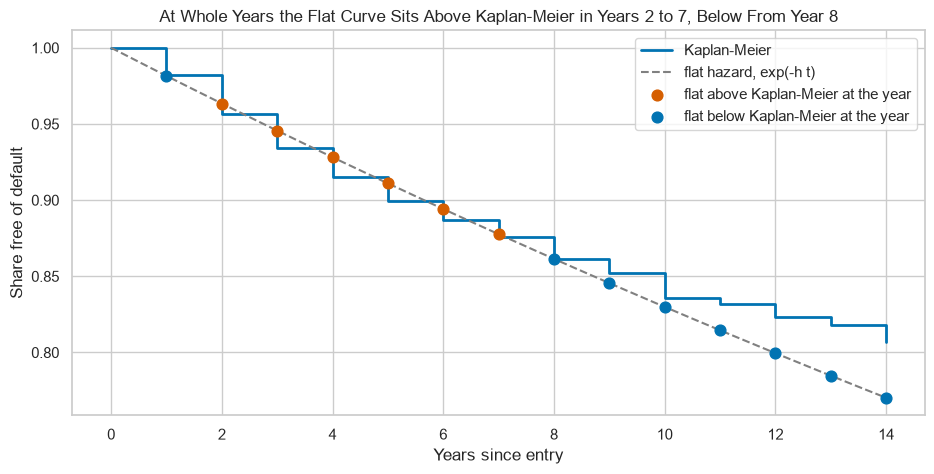

In [40]:
# Kaplan-Meier's steps, the smooth flat curve, and the flat curve read at each whole year, coloured by the sign of its gap
t = np.linspace(0, 14, 141)
above = flat["flat less Kaplan-Meier"] > 0
plt.figure(figsize=(11, 5))
plt.step(np.append(0, flat.index), np.append(1, flat["Kaplan-Meier"]), where="post", linewidth=2, label="Kaplan-Meier")
plt.plot(t, np.exp(-flat_h * t), linewidth=1.5, linestyle="--", color="gray", label="flat hazard, exp(-h t)")
plt.scatter(flat.index[above], flat.loc[above, "flat"], s=60, color="C3", zorder=3, label="flat above Kaplan-Meier at the year")
plt.scatter(flat.index[~above], flat.loc[~above, "flat"], s=60, color="C0", zorder=3, label="flat below Kaplan-Meier at the year")
plt.xlabel("Years since entry")
plt.ylabel("Share free of default")
plt.title("At Whole Years the Flat Curve Sits Above Kaplan-Meier in Years 2 to 7, Below From Year 8")
plt.legend()
plt.show()

The flat rate misses the bump in years 2 to 4 and the quieter years after, so it sits above early and below late.

Predict 3's running product with every factor the same, `(1 - flat_h) ** 14`, gives 0.7684 beside exp(-14 h)'s 0.7703: the exponential is that product's smooth form.

**One rate summarises 14 years fairly and describes no single one of them.**

# The Credit Triangle

## A Spread, a Recovery, a Hazard

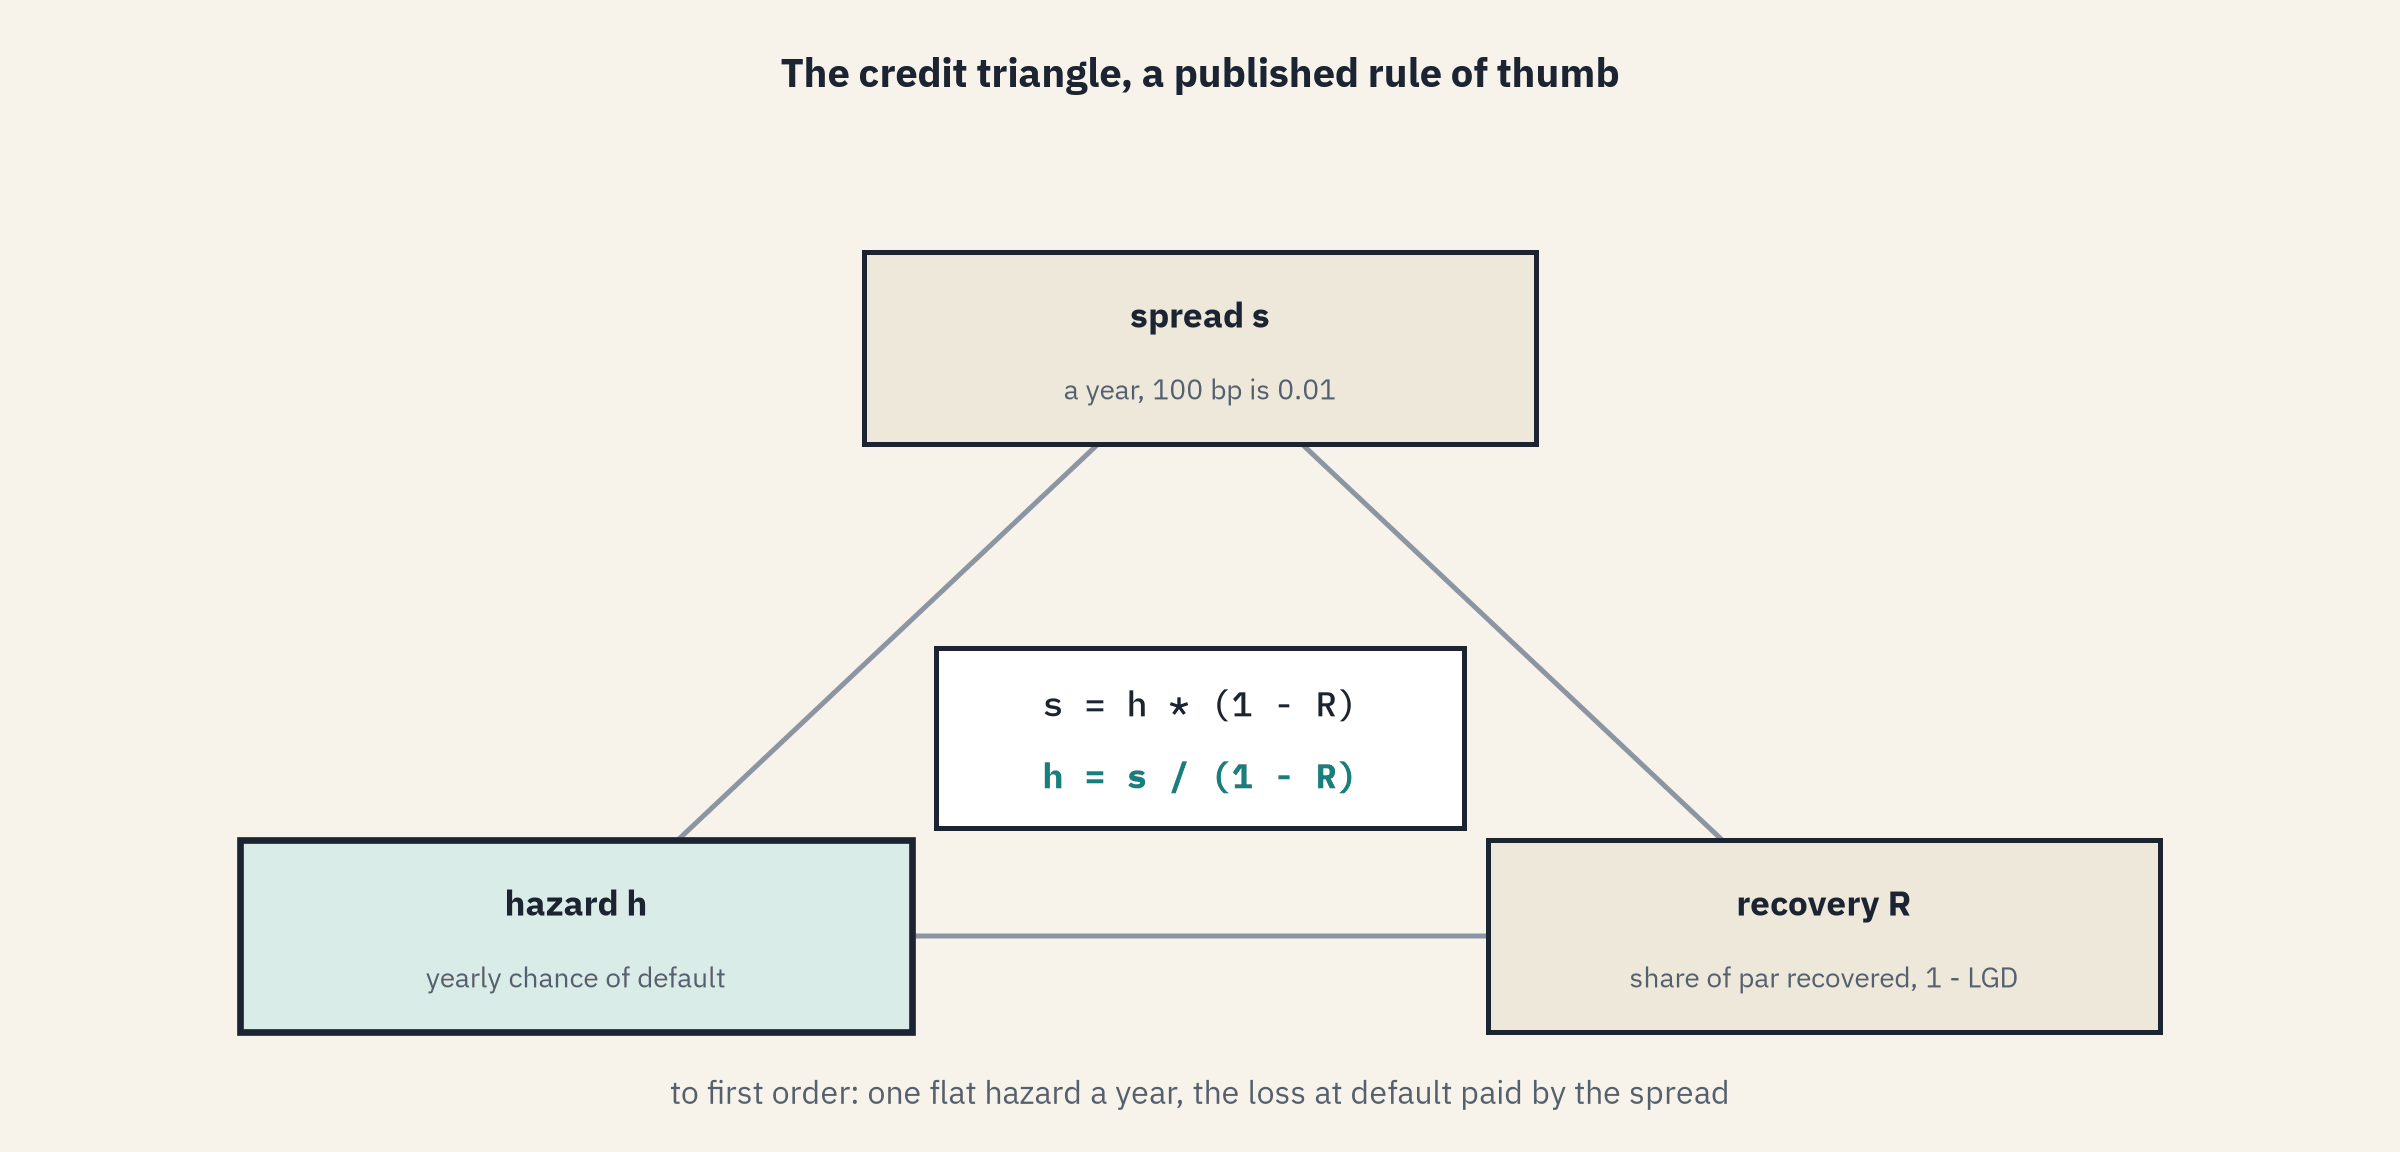

The **credit triangle**, a published rule of thumb: to first order s = h (1 - R), so h = s / (1 - R).
The spread and recovery below are invented, and R = 0.40 is 1 less Day 1's invented LGD of 0.60.
The arithmetic runs one way only, from an invented spread to a hazard.

**Predict 5**

Q. At an invented spread of 250 bp and 40 percent recovery, what is the chance of a default within 5 years under the flat hazard the triangle gives? Write down a percent.

## Three Invented Spreads

In [41]:
# the hazard and the chance of a default within 5 years, 1 - exp(-5 h), at three invented spreads
RECOVERY = 0.40
triangle = pd.DataFrame({"spread_bp": [100, 250, 500]})
triangle["hazard_pct"] = 100 * triangle["spread_bp"] / 10_000 / (1 - RECOVERY)
triangle["default_within_5_pct"] = 100 * (1 - np.exp(-5 * triangle["hazard_pct"] / 100))
triangle.round(2)

,spread_bp,hazard_pct,default_within_5_pct
0,100,1.67,8.00
1,250,4.17,18.81
2,500,8.33,34.08


## Your Turn: Any Spread and Recovery

In [42]:
# the share free of default over 10 years under the triangle's flat hazard, the 5-year point marked
def draw_triangle(spread_bp=250, recovery=0.40):
    h = spread_bp / 10_000 / (1 - recovery)
    years = np.linspace(0, 10, 101)
    plt.figure(figsize=(11, 4.5))
    plt.plot(years, 100 * np.exp(-h * years), linewidth=2)
    plt.scatter(5, 100 * np.exp(-5 * h), color="C3", s=80, zorder=3)
    plt.ylim(0, 101)
    plt.xlabel("Years")
    plt.ylabel("Share free of default (percent)")
    plt.title(f"{spread_bp} bp at {100 * recovery:.0f} Percent Recovery: Hazard {100 * h:.2f} Percent a Year, Default Within 5 Years {100 * (1 - np.exp(-5 * h)):.1f} Percent")
    plt.show()

In [43]:
# your turn: move the invented spread and recovery
interact(draw_triangle, spread_bp=(50, 1000, 50), recovery=(0.0, 0.8, 0.05));

interactive(children=(IntSlider(value=250, description='spread_bp', max=1000, min=50, step=50), FloatSlider(va…

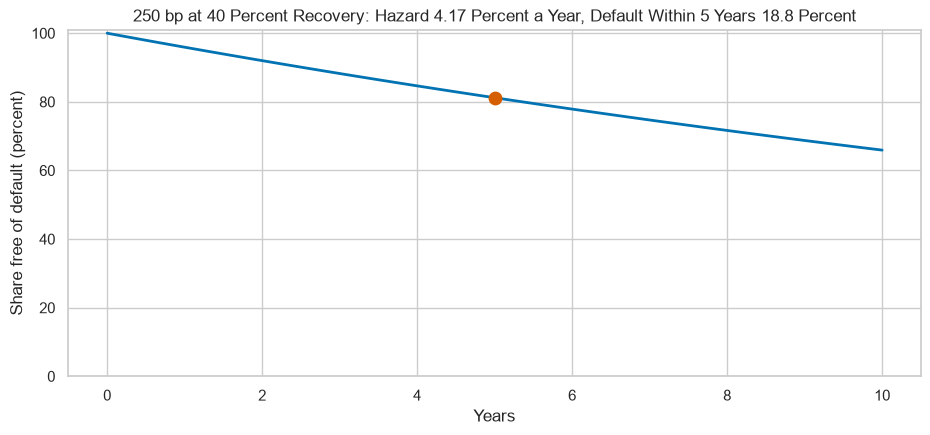

In [44]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_triangle(spread_bp=250, recovery=0.40)

At a higher recovery the same spread pays for more defaults, so the hazard rises.

**A flat hazard is the bridge from a spread to a default chance; the numbers are invented, the arithmetic is not.**

# Insights and Conclusion

90.2 percent of the firms ended their watch censored, by an exit or by the end of year 14.

On ten firms the running product ended at 0.5, where counting every firm to the end gave 0.7.

Past 14 years, dropping the censored firms left 17.3 percent free of default and Kaplan-Meier 80.7 percent.

Greenwood's standard error grew from 0.0022 at year 1 to 0.0163 at year 14, on 73 firms.

Past 10 years 98.5 percent of investment grade entrants and 21.2 percent of CCC entrants were free of default; AA against A could not be read on 2 defaults.

The hazard peaked in year 2 after entry; one flat rate, 1.86 percent a year, ran above the curve early and below it late.

An invented 250 bp at 40 percent recovery gave an 18.8 percent chance of default within 5 years.

**Count every firm for the years it was watched, and no longer.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Turn firm-years into one row per firm with a time and an event, and tell a default from a censored watch.
* Work Kaplan-Meier by hand and as a function, and say how dropping censored firms or counting them as survivors goes wrong.
* Fit a survival curve with `SurvfuncRight` and read Greenwood's band.
* Compare curves by group and test their gap with the log-rank test.
* Read a hazard year by year, its cumulative sum, and a flat hazard's curve.
* Turn an invented spread and recovery into a hazard and a default chance with the credit triangle.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [45]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The BBB Entrants**

Q. With `kaplan_meier`, store the share of the firms that entered at BBB (`entry_bucket`) still free of default past 10 years in `ex1_survival_10`.

In [46]:
# the BBB entrants' curve from the lesson's kaplan_meier, read past 10 years
bbb_entrants = firms[firms["entry_bucket"] == "BBB"]
bbb_curve = kaplan_meier(bbb_entrants["years"], bbb_entrants["defaulted"])
ex1_survival_10 = bbb_curve.loc[10, "survival"]
print(f"BBB entrants past 10 years: {ex1_survival_10:.4f} | firms: {len(bbb_entrants)} | defaults: {bbb_entrants['defaulted'].sum()} | at risk at 10: {bbb_curve.loc[10, 'at_risk']}")

BBB entrants past 10 years: 0.9763 | firms: 878 | defaults: 13 | at risk at 10: 164


The curve rests on 13 defaults among 878 firms, so each one moves it by a step you can see.

In [47]:
check("Exercise 1 BBB entrants past 10 years", ex1_survival_10, 0.97633165550907)

Exercise 1 BBB entrants past 10 years: correct


### Exercise 2

**A Wider Spread**

Q. At an invented spread of 400 bp and an invented recovery of 40 percent, store the credit triangle's chance of a default within 5 years in `ex2_default_5`, as a fraction.

In [48]:
# the triangle's hazard at an invented 400 bp and 40 percent recovery, then the chance of a default within 5 years
hazard_400 = 400 / 10_000 / (1 - 0.40)
ex2_default_5 = 1 - np.exp(-5 * hazard_400)
print(f"Hazard {100 * hazard_400:.2f} percent a year | default within 5 years {100 * ex2_default_5:.1f} percent")

Hazard 6.67 percent a year | default within 5 years 28.3 percent


In [49]:
check("Exercise 2 default within 5 years at 400 bp", ex2_default_5, 0.28346868942621073)

Exercise 2 default within 5 years at 400 bp: correct


### Exercise 3

**Nelson-Aalen as a Function**

Q. Write `nelson_aalen(time, event)`, with a one-line docstring, which returns the cumulative hazard at each distinct time from `kaplan_meier`'s `at_risk` and `events`. Store the CCC entrants' cumulative hazard at 5 years in `ex3_cumulative_5`.

In [50]:
# Nelson-Aalen on kaplan_meier's table: the running sum of events over at risk
def nelson_aalen(time, event):
    """The cumulative hazard at each distinct time: the running sum of events over at risk."""
    table = kaplan_meier(time, event)
    return np.cumsum(table["events"] / table["at_risk"])

# the CCC entrants' cumulative hazard at 5 years, beside minus the log of their curve
ccc_entrants = firms[firms["entry_bucket"] == "CCC"]
ex3_cumulative_5 = nelson_aalen(ccc_entrants["years"], ccc_entrants["defaulted"]).loc[5]
print(f"Nelson-Aalen at 5: {ex3_cumulative_5:.4f} | minus the log of S: {-np.log(group_km['CCC'].loc[5, 'survival']):.4f}")

Nelson-Aalen at 5: 0.8391 | minus the log of S: 0.9271


With CCC's large yearly hazards the two routes part, 0.8391 against 0.9271: the closeness the lesson saw holds only while hazards are small.

In [51]:
check("Exercise 3 CCC entrants' cumulative hazard at 5 years", ex3_cumulative_5, 0.8391324761865151)

Exercise 3 CCC entrants' cumulative hazard at 5 years: correct


### Exercise 4: AI check

**An Exit Is Not a Default**

You asked an AI assistant for a function that turns firm-years into one row per firm with a time and an event.
This came back.
Test it against its own docstring, then find the one bug.

In [52]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def firm_outcomes(rows):
    """One row per firm: its time (last years_since_entry) and its event (1 for a default; an exit or a firm still watched is censored, 0)."""
    last = rows.groupby("firm_id").agg(time=("years_since_entry", "max"), default=("default", "max"), exit=("exit", "max"))
    last["event"] = ((last["default"] == 1) | (last["exit"] == 1)).astype(int)
    return last[["time", "event"]]

In [53]:
# the test: one event per default in the rows, and the curve past 10 years against the lesson's
outcomes = firm_outcomes(development)
print("Events:", outcomes["event"].sum(), "| defaults in the rows:", development["default"].sum())
print(f"Past 10 years: {kaplan_meier(outcomes['time'], outcomes['event']).loc[10, 'survival']:.4f} | the lesson's {km.loc[10, 'survival']:.4f}")

Events: 1576 | defaults in the rows: 345
Past 10 years: 0.4201 | the lesson's 0.8359


Q. Fix the one wrong line, rerun the test, and store the fixed curve's share free of default past 10 years in `ex4_survival_10`.

In [54]:
# the fix: only a default is an event; an exit is censored, as the docstring says
def firm_outcomes(rows):
    """One row per firm: its time (last years_since_entry) and its event (1 for a default; an exit or a firm still watched is censored, 0)."""
    last = rows.groupby("firm_id").agg(time=("years_since_entry", "max"), default=("default", "max"), exit=("exit", "max"))
    last["event"] = last["default"]
    return last[["time", "event"]]

outcomes = firm_outcomes(development)
ex4_survival_10 = kaplan_meier(outcomes["time"], outcomes["event"]).loc[10, "survival"]
print("Events:", outcomes["event"].sum(), "| defaults in the rows:", development["default"].sum(), f"| past 10 years: {ex4_survival_10:.4f}")

Events: 345 | defaults in the rows: 345 | past 10 years: 0.8359


The planted line counted every exit as an event, so 1,231 firms that left for a reason unrelated to default were read as defaults.

With only defaults as events the count matches the rows, and the curve gives back the lesson's 0.8359.

In [55]:
check("Exercise 4 the fixed curve past 10 years", ex4_survival_10, 0.8359388586228113)

Exercise 4 the fixed curve past 10 years: correct


## Congratulations!

You followed 3,504 invented firms from entry to the end of their watch, and saw that nine in ten never show you a default.
You worked Kaplan-Meier by hand, wrote it in four lines, and watched two tempting shortcuts sink and float the curve.
Then you read the curve's band, split it by rating, tested the gaps, and found a bump in the hazard that one flat rate smooths away.
In Day 5 the firm-years come back as rows, and a hazard model gives every firm-year its own default probability.

[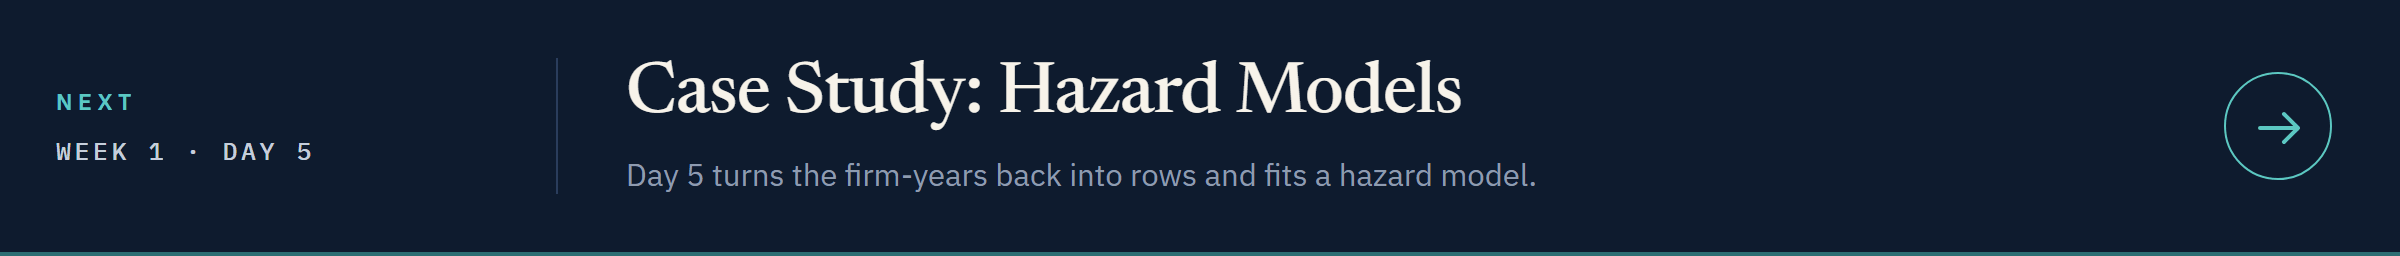](../day5/05_case_study_hazard_models.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day5/05_case_study_hazard_models.ipynb)